## 04 · EMT-TF expression (unconditional — final notebook)

The EMT-TF step runs regardless of gate outcome and is always the *last* notebook (here
**04**, since Gate 3 = NA). We score a widened EMT-TF panel — including the FOXC and PRRX
mesenchymal families, not only Snail/Zeb/Twist — **gated on detectable expression**, and
overlay the thresholded expressers of the two most informative factors on a grey manifold
(the reference categorical style, not a continuous colormap). VIM is a mesenchymal marker,
**not** a transcription factor, and is excluded.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth = os.path.join(*([os.pardir]*6)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

In [3]:
# read the manifold with signatures + pseudotime; reuse the house linear layout
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']
t = adata.obs['t'].values; tn = (t - t.min())/(t.max() - t.min())
print('cells:', adata.shape[0], '| pseudotime', round(t.min(), 2), '->', round(t.max(), 2))

cells: 2118 | pseudotime 0.0 -> 10.3


In [4]:
# widened EMT-TF panel gated on detectable expression (eval lesson). VIM excluded.
# per-TF: detection frac, pseudotime trend (rho), and enriched-end bias.
panel = ['SNAI1', 'SNAI2', 'ZEB1', 'ZEB2', 'TWIST1', 'TWIST2',
         'FOXC1', 'FOXC2', 'PRRX1', 'PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:, present].X; X = X.toarray() if hasattr(X, 'toarray') else np.asarray(X)
rows = []
for j, g in enumerate(present):
    x = X[:, j]; rho, p = spearmanr(tn, x); me, ml = x[early].mean(), x[late].mean()
    bias = (ml - me)/(ml + me + 1e-9)                      # +1 pure terminus, -1 pure root
    rows.append((g, round((x > 0).mean(), 3), round(me, 3), round(ml, 3),
                 round(rho, 3), round(bias, 3)))
df = pd.DataFrame(rows, columns=['TF', 'frac_expr', 'mean_early', 'mean_late', 'rho_vs_t', 'end_bias'])
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
# legibility floor: a factor's top-decile overlay must be >=15 cells, else the categorical
# overlay is a degenerate speck (the 'washed-out' failure mode). This keeps broadly-expressed
# mesenchymal factors and drops the barely-detectable ones (e.g. SNAI2 at ~3%).
frac_floor = 15 / adata.shape[0] / 0.10                   # >=15 cells in the top expresser decile
ok = df[df.frac_expr > frac_floor].copy()
print(f'detectability floor frac_expr > {frac_floor:.3f} (>=15 cells in top decile)')
tf_lo = ok.sort_values('rho_vs_t').iloc[0]['TF']          # most root-trending legible factor
tf_hi = ok.sort_values('rho_vs_t').iloc[-1]['TF']         # most terminus-trending legible factor
def _end_label(g):
    b = float(ok.loc[ok.TF == g, 'end_bias'].iloc[0])
    return 'terminus' if b > 0.05 else ('root' if b < -0.05 else 'pan-tumor')
lab_lo, lab_hi = _end_label(tf_lo), _end_label(tf_hi)
print(f'\nlegible factors (pass detectability floor): {ok.TF.tolist()}')
print(f'derived pair: {tf_lo} ({lab_lo}) <-> {tf_hi} ({lab_hi})')

    TF  frac_expr  mean_early  mean_late  rho_vs_t  end_bias
TWIST2      0.001       0.002      0.000    -0.017    -1.000
 FOXC1      0.002       0.007      0.006    -0.007    -0.029
 FOXC2      0.002       0.008      0.001     0.001    -0.679
 PRRX2      0.012       0.048      0.035     0.004    -0.155
TWIST1      0.002       0.002      0.009     0.018     0.677
 SNAI2      0.033       0.133      0.170     0.025     0.123
 PRRX1      0.578       2.219      2.254     0.026     0.008
 SNAI1      0.083       0.326      0.328     0.036     0.002
  ZEB1      0.781       2.938      3.857     0.153     0.135
  ZEB2      0.771       2.424      3.371     0.172     0.163
detectability floor frac_expr > 0.071 (>=15 cells in top decile)

legible factors (pass detectability floor): ['PRRX1', 'SNAI1', 'ZEB1', 'ZEB2']
derived pair: PRRX1 (pan-tumor) <-> ZEB2 (terminus)


overlay thresholds (top decile among expressers): {'PRRX1': 5.24, 'ZEB2': 5.18} | cells shown: {'PRRX1': 123, 'ZEB2': 164}
PRRX1: 57.8% expressing; 123 shown (top decile), mean pseudotime of shown = 0.50 (all = 0.48)
ZEB2: 77.1% expressing; 164 shown (top decile), mean pseudotime of shown = 0.43 (all = 0.48)
saved expression.pdf


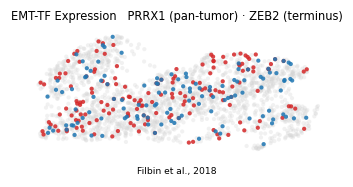

In [5]:
# deliverable: expression.pdf -- categorical overlay of thresholded expressers on a grey
# manifold (house 3.5,1.5). threshold = top decile among expressers, per factor, so a
# broadly-expressed TF is not washed across the whole manifold.
xl = adata.obsm['X_umap']
xlo, xhi = np.percentile(xl[:, 0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:, 1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
def _vec(g):
    x = adata[:, g].X
    return x.toarray().ravel() if hasattr(x, 'toarray') else np.asarray(x).ravel()
thr = {}
for g in [tf_lo, tf_hi]:
    v = _vec(g); pos = v[v > 0]; thr[g] = float(np.quantile(pos, 0.90)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [tf_lo, tf_hi]}
print('overlay thresholds (top decile among expressers):', {g: round(thr[g], 2) for g in thr},
      '| cells shown:', {g: int(sel[g].sum()) for g in sel})
order = sorted([tf_lo, tf_hi], key=lambda g: -int(sel[g].sum()))
colors = {tf_lo: 'tab:blue', tf_hi: 'tab:red'}
labs = {tf_lo: lab_lo, tf_hi: lab_hi}
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.85, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title(f'EMT-TF Expression   {tf_lo} ({labs[tf_lo]}) \u00b7 {tf_hi} ({labs[tf_hi]})', size=7.5)
ax.text(.5, -.14, 'Filbin et al., 2018', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'expression.pdf'), bbox_inches='tight')
for g in [tf_lo, tf_hi]:
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(sel[g].sum())} shown (top decile), '
          f'mean pseudotime of shown = {tn[sel[g]].mean():.2f} (all = {tn.mean():.2f})')
print('saved expression.pdf')